# Sea Surface Salinity

Projected sea surface salinity near the selected site from the decadal projections of Jiang et al. (2023).

```{glue:figure} salinity_maps_fig
:scale: 60%
:align: center
```

**Figure. Sea surface salinity at the site under SSP2-4.5** (median ± standard deviation across Earth system models), with maps of the surrounding region for each decade.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Import libraries and helper functions. Projection plotting utilities come from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository (`ind_setup.plotting_projections`); data access, site configuration and output helpers come from `functions/projections.py` and `functions/site_common.py`.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
from ind_setup.plotting_projections import plot_timeseries_with_mini_maps

sys.path.append("../../../../functions")
from site_common import load_site_config, list_available_sites, site_config_filename, build_site_tag, build_site_figures_dir, build_site_tables_dir
import projections as prj
import cmocean

### Define location

Set `site_key` to one of the sites configured with [`../../../historical/National/00_site_setup.ipynb`](../../../historical/National/00_site_setup.ipynb) (see the list printed below). The notebook reads the coordinates and country from `data/sites/<site_key>.json`, exactly as the historical notebooks do.

In [3]:
sites_dir = Path("../../../../data/sites")
available_sites = list_available_sites(sites_dir)
print(f"{len(available_sites)} site(s) already configured in {sites_dir}:")
display(available_sites)

6 site(s) already configured in ../../../../data/sites:


,site_key,site_name,country,ghcn_station_id,ghcn_station_name,vars_interest
0,cook_islands_new_zealand_cwm00091843,cook_islands_new_zealand_CWM00091843,Cook Islands [New Zealand],CWM00091843,RAROTONGA INTL GSN 91843,"[TMIN, TMAX, PRCP]"
1,marshall_islands_rmw00040604,marshall_islands_RMW00040604,Marshall Islands,RMW00040604,MH KWAJALEIN GSN 91366,"[TMIN, TMAX, PRCP]"
2,marshall_islands_rmw00040710,marshall_islands_RMW00040710,Marshall Islands,RMW00040710,MH MAJURO WBAS AP GSN 91376,"[TMIN, TMAX, PRCP]"
3,niue_new_zealand_nem00091824,niue_new_zealand_NEM00091824,Niue [New Zealand],NEM00091824,HANAN AIRPORT GSN 91824,"[TMIN, TMAX, PRCP]"
4,palau,Palau,Palau,None,None,None
5,palau_psw00040309,palau_PSW00040309,Palau,PSW00040309,PW KOROR GSN 91408,"[TMIN, TMAX, PRCP]"


In [4]:
site_key = "palau_psw00040309"  # pick a site_key from the table printed above

site_cfg = load_site_config(sites_dir / site_config_filename(site_key))

site_name = site_cfg.get("site_name", "Site")
site_lon = float(site_cfg["site_lon"])
site_lat = float(site_cfg["site_lat"])
country = site_cfg.get("country", site_name)
site_label = country

site_tag = build_site_tag(site_name, site_lon, site_lat)
fig_dir = build_site_figures_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
tables_dir = build_site_tables_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
cache_dir = prj.site_cache_dir(site_tag)
print(f"{country}: lon {site_lon}, lat {site_lat} -> figures in {fig_dir}")

Palau: lon 134.4769, lat 7.3367 -> figures in ../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477


## Analysis

### Surface ocean carbonate system

Decadal projections of the surface ocean carbonate system on a 1° grid (median and standard deviation of the CMIP6 Earth system models; [Jiang et al., 2023](https://www.ncei.noaa.gov/data/oceans/ncei/ocads/metadata/0259391.html), NOAA NCEI OCADS 0259391). The site value is read at the nearest ocean cell; the mini maps show a ±7° window around it.

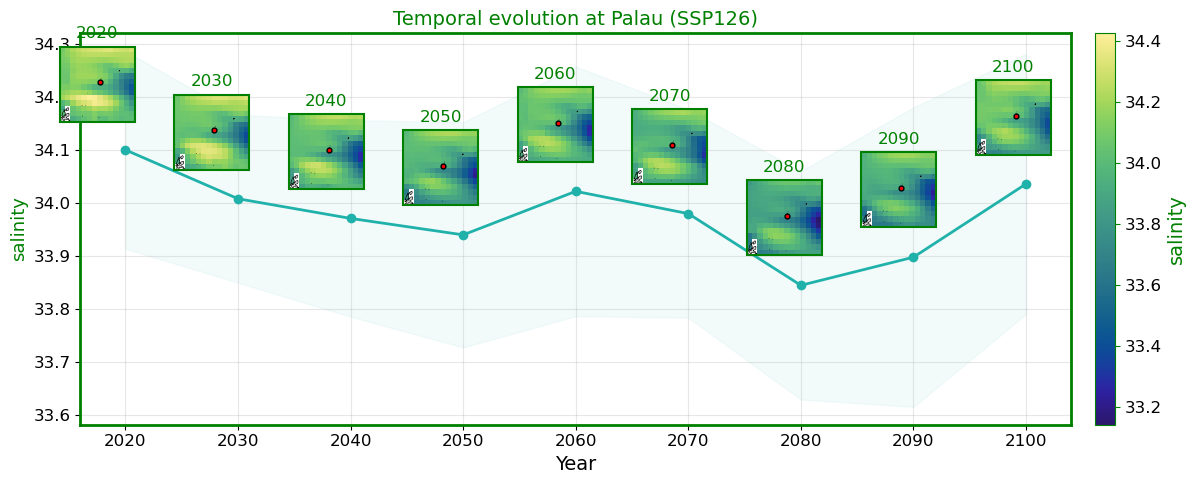

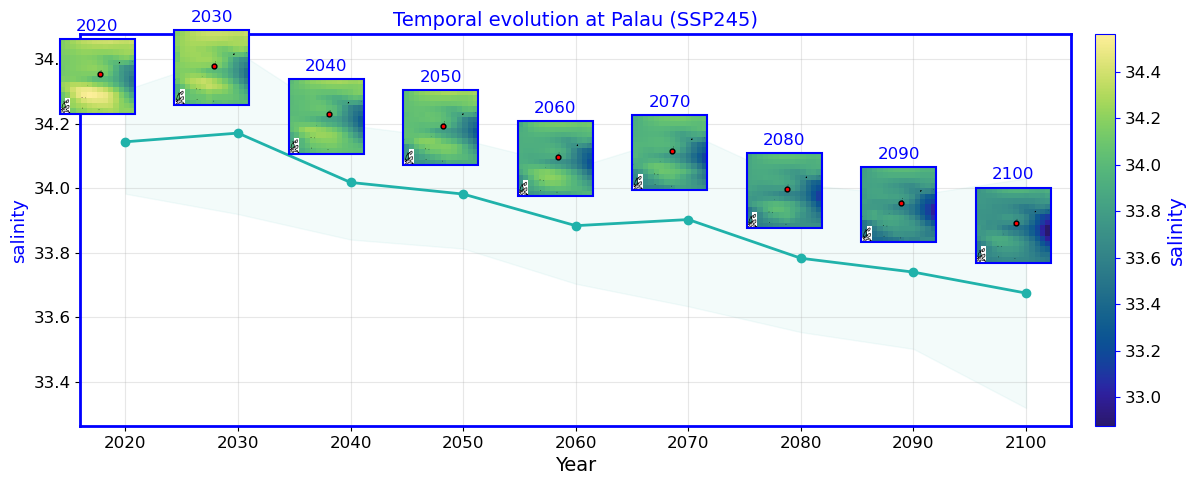

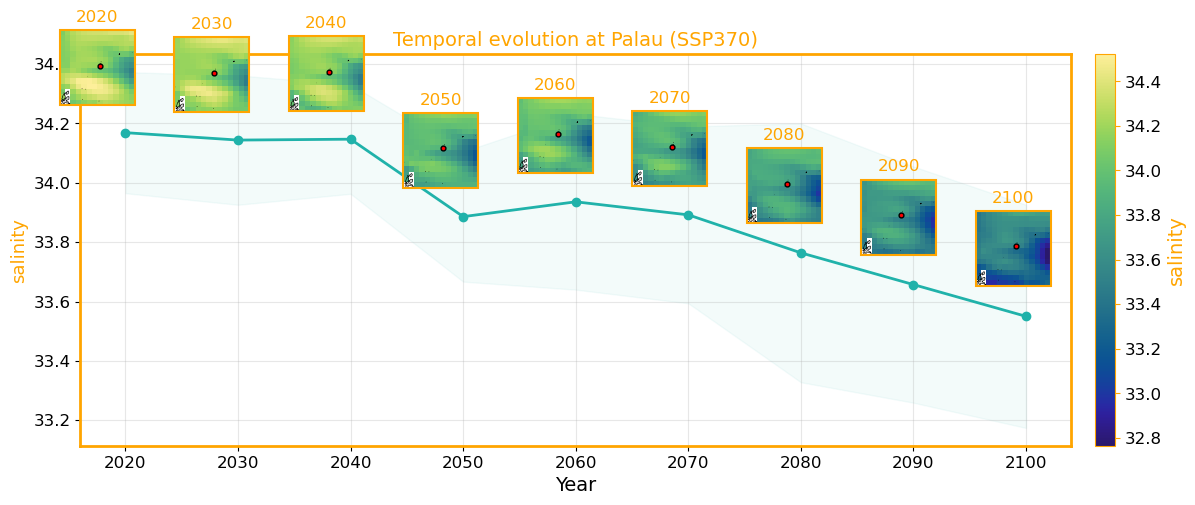

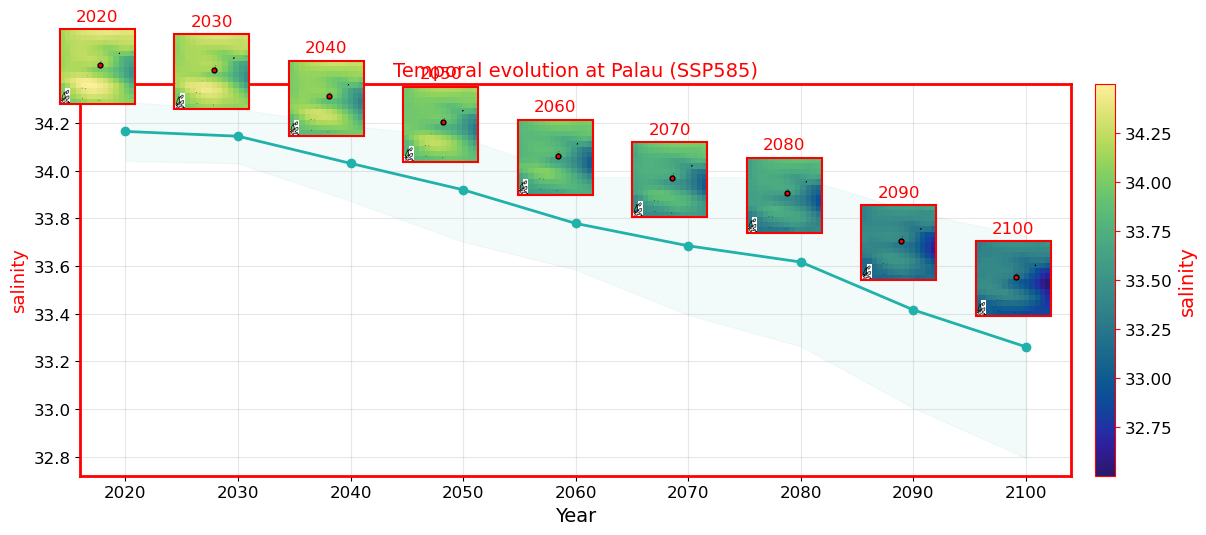

In [5]:
ocads_scenarios = ["ssp126", "ssp245", "ssp370", "ssp585"]

for scenario in ocads_scenarios:
    point, point_std, area = prj.ocads_site("salinity", scenario, site_lon, site_lat)
    fig = plot_timeseries_with_mini_maps(area, point, point_std, scenario=scenario, var_analysis="salinity",
                                         lon_lat=[site_lon % 360, site_lat], cmap=cmocean.cm.haline, c_line="lightseagreen",
                                         site_label=site_label)
    prj.save_figure(fig, fig_dir, f"salinity_maps_timeseries_{scenario}", site_tag)
    if scenario == "ssp245":
        glue("salinity_maps_fig", fig, display=False)

In [6]:
table = prj.ocads_table("salinity", ocads_scenarios, site_lon, site_lat)
prj.save_table(table, tables_dir, "salinity_ocads_decadal", site_tag, index=True)
table

,SSP126 median,SSP126 std,SSP245 median,SSP245 std,SSP370 median,SSP370 std,SSP585 median,SSP585 std
Year,,,,,,,,
2020,34.100,0.186,34.144,0.161,34.169,0.204,34.164,0.123
2030,34.008,0.158,34.171,0.251,34.144,0.218,34.144,0.114
2040,33.971,0.185,34.018,0.177,34.147,0.184,34.030,0.158
2050,33.940,0.212,33.982,0.169,33.886,0.219,33.919,0.218
2060,34.022,0.235,33.884,0.180,33.936,0.296,33.778,0.194
2070,33.980,0.196,33.903,0.269,33.892,0.298,33.684,0.289
2080,33.845,0.215,33.783,0.229,33.764,0.436,33.616,0.354
2090,33.898,0.282,33.740,0.238,33.657,0.398,33.415,0.411
2100,34.036,0.245,33.675,0.356,33.550,0.376,33.260,0.466
